# How to: Analyze Critical Components

This tutorial demonstrates pandaICT's powerful and efficient **critical component analysis** feature for sensitivity analysis of network reliability.

## The "Last-Straw" Critical Component Concept

During Monte Carlo simulation, whenever the network transitions from operational to failed (or vice versa), we record **which component's state change caused that system-level transition**. This component is called the "last straw" - it was the final piece that tipped the system into failure.

**Key Insight**: By collecting these "last straw" events across all simulations, we can identify which components disproportionately contribute to system failures.

## Why This Is Efficient

Traditional sensitivity analysis approaches require re-running the full Monte Carlo simulation for each component to assess its importance. This results in:

| Approach | Computational Cost | Description |
|----------|------------------|-------------|
| **Traditional** | O(n x N) | Run N simulations for each of n components |
| **Our Approach** | O(N) | Extract from existing simulations at O(1) cost per run |

Our approach extracts criticality information **for free** during the MTTF/MTTR estimation, with effectively zero additional computational overhead.

In [1]:
import pandaict as pi
from pandaict import inspect
from pandaict.utils.enums import *
from pandaict.reliability.reliability import (
    estimate_mtbf_mttr_for_conn,
    analyze_critical_components_for_conn,
    plot_graph
)
from pandaict.topology.routing import calc_routes_for_connection

from demo_networks import (
    simple_serial_chain_net,
    two_source_parallel_net,
    parallel_with_backbone_net,
    heterogeneous_rate_net,
    net_hardened,
    net_parallel_hardened
)

---

## The Mathematical Foundation

After all simulations complete, we compare the **observed** failure frequency with the **expected** failure frequency:

### Key Formulas

**Observed fraction** (how often component j caused failure):
$\hat{p}_j^{obs} = \frac{f_j^{obs}}{\sum_i f_i^{obs}}$

**Expected fraction** (based on transition rate):
$\hat{p}_j^{exp} = \frac{r_j}{\sum_i r_i}$

**Criticality score**:
$C_j = \frac{\hat{p}_j^{obs}}{\hat{p}_j^{exp}}$

### Interpretation

| Score | Meaning | Action |
|-------|---------|--------|
| **> 1** | MORE critical than expected | Structural bottleneck - consider hardening |
| **~ 1** | As critical as expected | Normal failure rate |
| **< 1** | LESS critical than expected | Has redundancy protection |

---

## Example 1: Serial Chain - Equal Structural Criticality

Let's start with the simplest case: a serial chain where all components are equally critical.

**Topology:**
```
   [Alice] -- NodeA -- NodeB -- NodeC -- NodeD -- [Bob]
```

In a serial chain, every component is a single point of failure. If ANY node fails, the entire system fails. Therefore, all components should have **equal topological criticality**.

In [2]:
# Create the serial chain network
net, appA, appB = simple_serial_chain_net()

# Create connection
conn = pi.create_ict_connection(net, name='Conn', from_app=appA, to_app=appB, protocol='TCP')

print("Network: Simple Serial Chain")
print("-" * 40)
print(net.node['mtbf_h'])
print("-" * 40)

Network: Simple Serial Chain
----------------------------------------
0    8760.0
1    8760.0
2    8760.0
3    8760.0
Name: mtbf_h, dtype: float64
----------------------------------------


As always lets plot the corresponding graph:

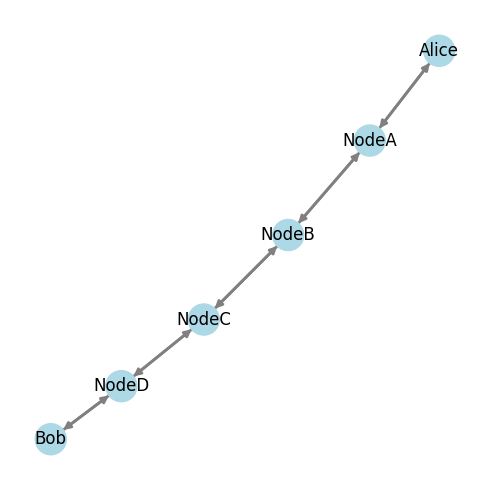

In [3]:
plot_graph(net)

Running criticality analysis...

>>> All components have EQUAL structural importance
>>> Expected: All scores should be ~1.0

Running 2000000 (10000 x 200) simulations in parallel...


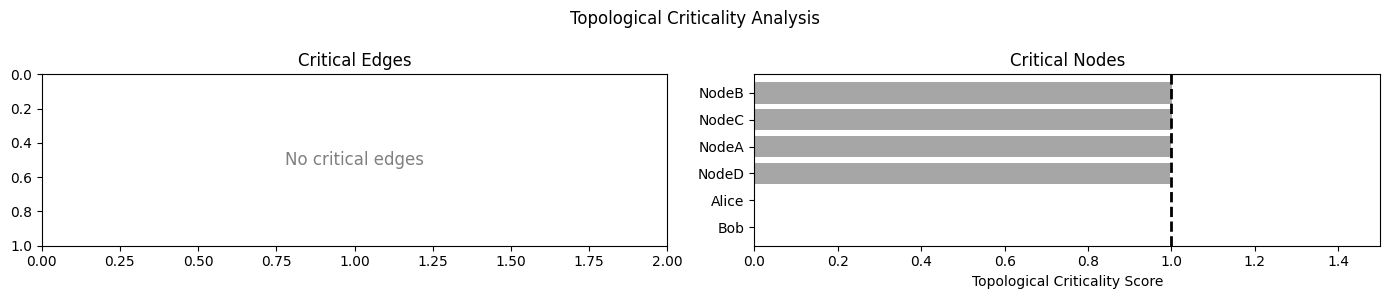

In [4]:
# Run criticality analysis with rate_adjustment=True
print("Running criticality analysis...")
print("\n>>> All components have EQUAL structural importance")
print(">>> Expected: All scores should be ~1.0\n")

crit_result = analyze_critical_components_for_conn(
    net, [conn],
    N=10000,
    rate_adjustment=True,  # Topological criticality
    verbose=False,
)

**Observation**: All nodes have criticality scores around 1.0, confirming that in a serial chain, all components are equally critical from a topological perspective.

---

## Example 2: Parallel Network - Identifying Redundancy

Now let's examine a network with parallel paths where some components have redundancy protection.

**Topology:**
```
              +----[NodeA]----[NodeB]----+
            /                              \
[Alice]---+                                 +---[NodeE]---[Bob]
            \                              /
              +----[NodeC]----[NodeD]----+
```


- If NodeA fails: Path 1 fails, but Path 2 still works
- If NodeC fails: Path 2 fails, but Path 1 still works
- If NodeE fails: BOTH paths fail - this is a **shared component**

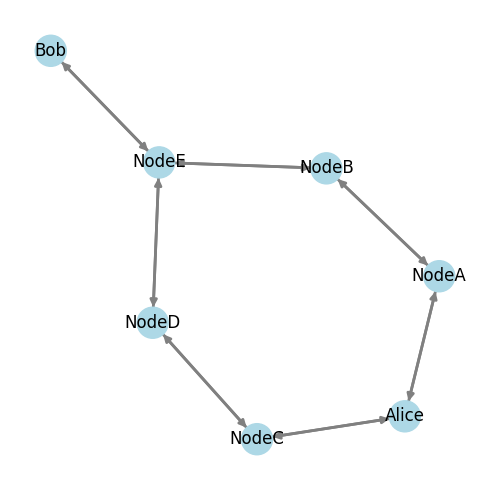

In [5]:
# Create the parallel network
net, appA, appB = two_source_parallel_net()

# Create connection (two paths)
conn = pi.create_ict_connection(net, name='conn', from_app=appA, to_app=appB, protocol='TCP')

plot_graph(net, seed=4)

Based on this topology we expect Node E to be a bottleneck since it appears on both paths between Alice and Bob. Nodes A, B, C and D on the other hand are redundant. Let's test that hypothesis as before:

Running 2000000 (10000 x 200) simulations in parallel...


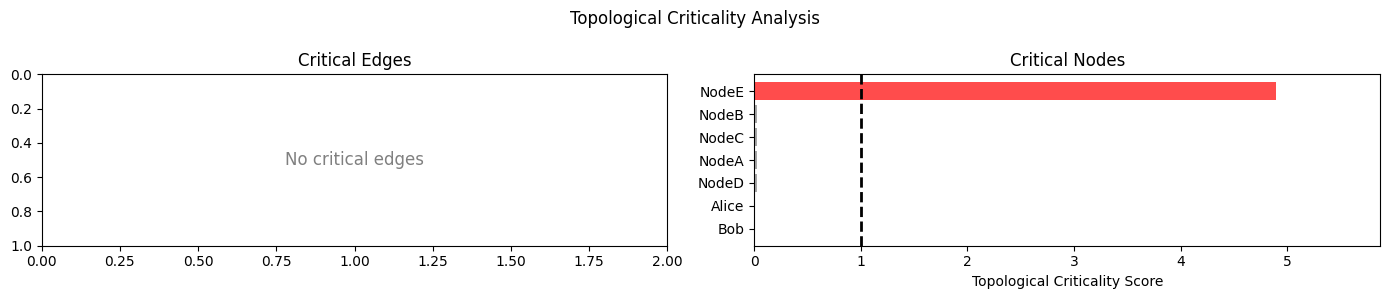

In [6]:
crit_result = analyze_critical_components_for_conn(
    net, [conn],
    N=10000,
    rate_adjustment=True,
    verbose=False
)

**Observation**: 

- **NodeE** shows a high criticality score (>>1.0) - it's a structural bottleneck
- **NodeA, NodeC, NodeB, NodeD** show lower scores (<1.0) - they have redundancy

This is powerful insight: the analysis automatically identifies where redundancy protection exists and where it doesn't!
This can be further visualized by using the `plot_graph` function we have used before and passing it the criticality scores of the components:

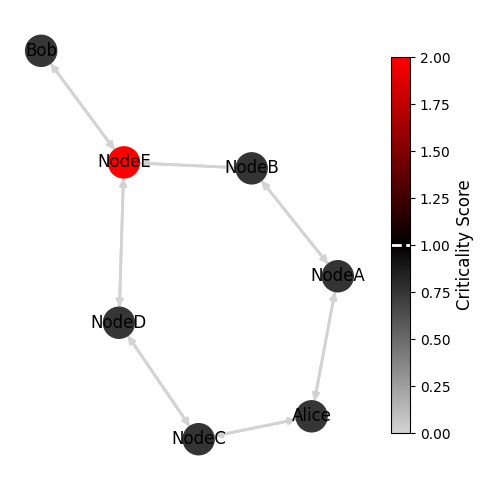

In [7]:
plot_graph(net,
           edge_criticality=crit_result['edge_criticality'],
           node_criticality=crit_result['node_criticality'],
           seed=4)

---

## Example 3: Mixed Network - Real-World Complexity

Let's examine a network with both parallel paths AND a shared backbone to see more nuanced criticality patterns.

**Topology:**
```
                     [NodeC]----[NodeD]
                    /                  \
[Alice]---[NodeA]-+                    +---[NodeE]---[Bob]
                    \                  /
                     [NodeB]----[NodeF]
```

**Components:**
- **Backbone (shared)**: NodeA, NodeE - appear in BOTH paths
- **Parallel (unique)**: NodeB, NodeC, NodeD, NodeF - unique to each path

We expect the backbone nodes to have higher topological criticality scores.

In [8]:
# Create the mixed network
net, appA, appB = parallel_with_backbone_net()

# Create two connections (two parallel paths)
conn = pi.create_ict_connection(net, name='Path1', from_app=appA, to_app=appB, protocol='TCP')


Running criticality analysis with min_connected=1...

>>> Expected: Backbone nodes (NodeA, NodeE) should have HIGHER scores
>>> Expected: Parallel nodes should have LOWER scores

Running 2000000 (10000 x 200) simulations in parallel...


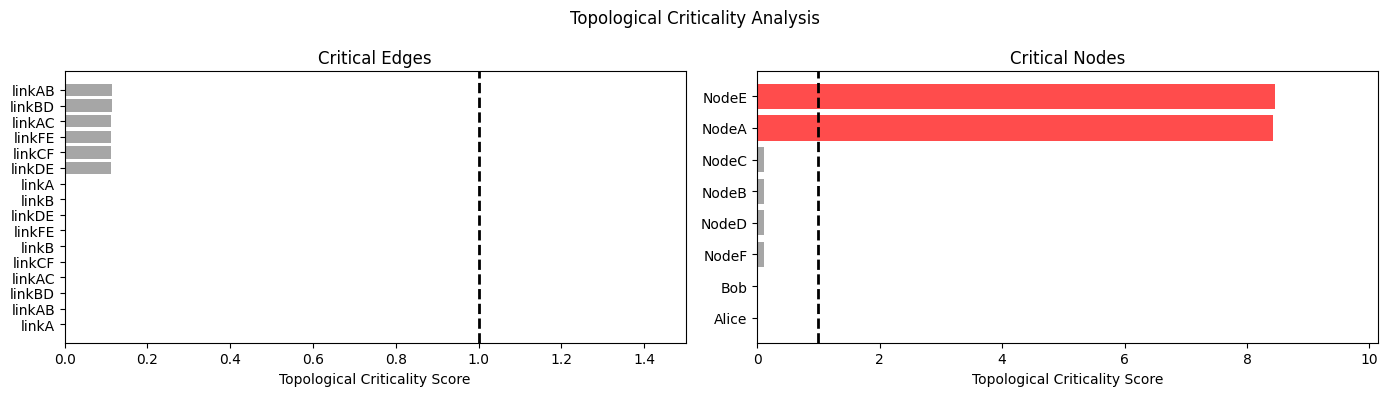

In [9]:
# Run criticality analysis
print("\nRunning criticality analysis with min_connected=1...")
print("\n>>> Expected: Backbone nodes (NodeA, NodeE) should have HIGHER scores")
print(">>> Expected: Parallel nodes should have LOWER scores\n")

crit_result = analyze_critical_components_for_conn(
    net, [conn],
    N=10000,
    rate_adjustment=True,
    verbose=False
)

**Observation**: 

- **NodeA and NodeE** (backbone) show the highest criticality scores - they are structural bottlenecks
- **NodeB, NodeC, NodeD, NodeF** (parallel) show lower scores - they have redundancy

This is exactly what we'd expect from the topology! The analysis automatically reveals the structural vulnerabilities.

---

## Deep Dive: `rate_adjustment` - True vs False

This is the key differentiating feature of the criticality analysis. The `rate_adjustment` parameter controls whether we normalize by failure rates.

### The Two Modes

| Parameter | Formula | Answers the Question                                             |
|-----------|---------|------------------------------------------------------------------|
| **`rate_adjustment=True`** | `(obs/Σobs) / (r/Σr)` | "Which components are **structurally** critical?"                |
| **`rate_adjustment=False`** | `obs/Σobs` | "What components will actually cause failures in the real world" |

### When to Use Each

- **Use `rate_adjustment=True`** for:
  - Identifying where to add redundancy
  - Structural hardening decisions
  - Long-term infrastructure planning

- **Use `rate_adjustment=False`** for:
  - Prioritizing maintenance resources
  - Allocating monitoring budgets
  - Operational decision-making

### Example Network: Heterogeneous Failure Rates

To clearly demonstrate the difference, consider a network where components have **different failure rates**:

**Topology:**
```
   [Alice] -- NodeA -- NodeB -- NodeC -- [Bob]
```

**All components are equally structurally critical** (all on the same serial path), but they have **very different failure rates**:

| Component | MTBF | Failure Rate | Operational Impact |
|-----------|------|--------------|---------------------|
| NodeA | 1,000 h | HIGH | Fails frequently |
| NodeB | 10,000 h | MEDIUM | Fails moderately |
| NodeC | 50,000 h | LOW | Rarely fails |

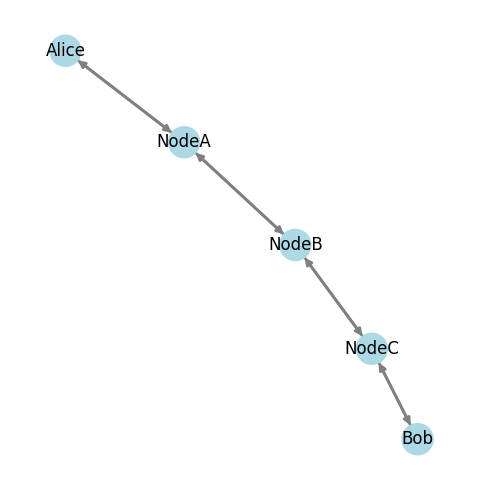

In [10]:
# Create network with heterogeneous failure rates
net, appA, appB = heterogeneous_rate_net()

# Create connection
conn = pi.create_ict_connection(net, name='Conn', from_app=appA, to_app=appB, protocol='TCP')

plot_graph(net)

Running 2000000 (10000 x 200) simulations in parallel...


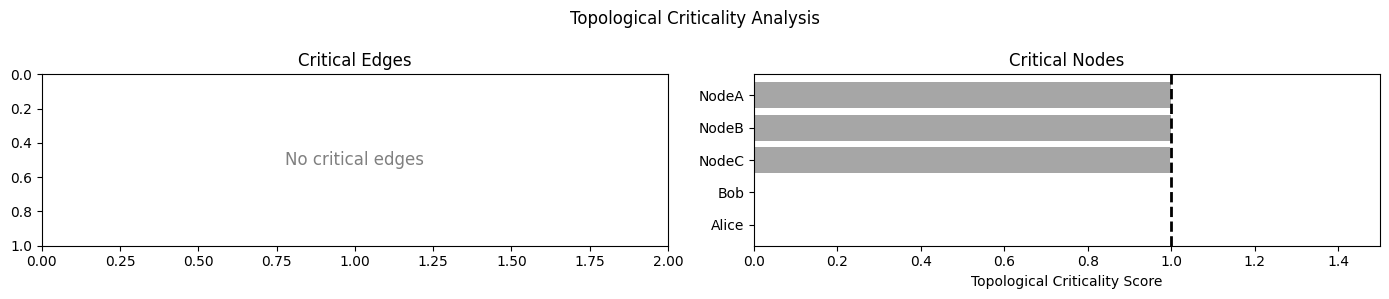

In [11]:
crit_topo = analyze_critical_components_for_conn(
    net, [conn],
    N=10000,
    rate_adjustment=True,
    verbose=False
)

Running 2000000 (10000 x 200) simulations in parallel...


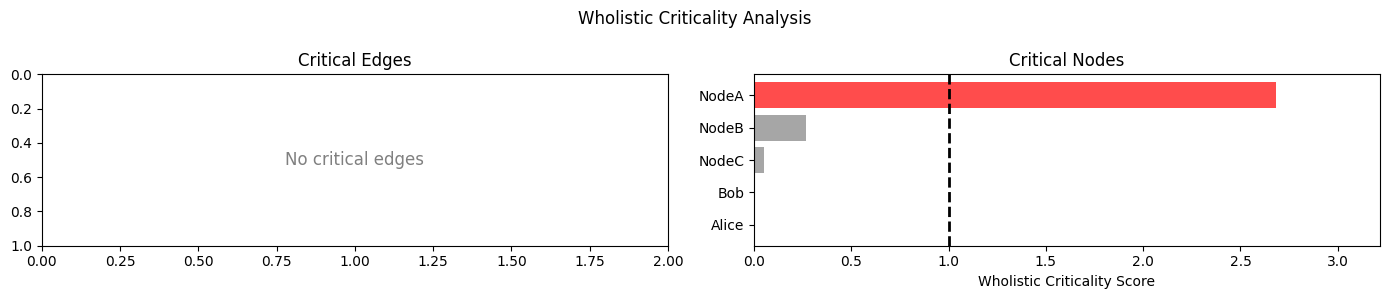

In [12]:

crit_raw = analyze_critical_components_for_conn(
    net, [conn],
    N=10000,
    rate_adjustment=False,
    verbose=False,
    plot=True
)

In [13]:
# Side-by-side comparison table
print("\n" + "=" * 70)
print("COMPARISON TABLE")
print("=" * 70)

# Extract node criticality scores
node_names = ['NodeA', 'NodeB', 'NodeC']
mtbfs = ['1,000 h', '10,000 h', '50,000 h']

print(f"{'Component':<12} {'MTBF':<12} {'Topological':<15} {'Raw Frequency':<15}")
print("-" * 70)

# Get criticality from results
topo_scores = crit_topo['node_criticality']
raw_scores = crit_raw['node_criticality']

for i, (name, mtbf) in enumerate(zip(node_names, mtbfs)):
    topo = topo_scores[i] if topo_scores[i] > 0 else 0.0
    raw = raw_scores[i] if raw_scores[i] > 0 else 0.0
    print(f"{name:<12} {mtbf:<12} {topo:<15.4f} {raw:<15.4f}")

print("-" * 70)



COMPARISON TABLE
Component    MTBF         Topological     Raw Frequency  
----------------------------------------------------------------------
NodeA        1,000 h      1.0001          2.6806         
NodeB        10,000 h     0.9999          0.2657         
NodeC        50,000 h     0.9960          0.0537         
----------------------------------------------------------------------


The interpretation here is clear: Structurally all components have the same importance but judged by raw frequencies Node A fails most often and in consequence triggers **systems level failures in 90%** of cases. This is an important insight when analyzing infrastructure for **effective resource and budget allocation**. A practical measure now would either be to **harden node A**, meaning to spend more resources on a more reliable component or to **add redundancy** for node A with a second component node A* parallel to node A.

### Key Insight

The two modes answer **different questions**:

1. **`rate_adjustment=True`** tells you: *"Which components are **structural bottlenecks**?"*
   - NodeA, NodeB, NodeC are equally important structurally
   - All need equal investment for network hardening

2. **`rate_adjustment=False`** tells you: *"Which component actually **causes failures**?"*
   - NodeA causes most failures → prioritize maintenance there
   - NodeC rarely fails → less maintenance needed

Or in other words: **`rate_adjustment=True`** tells you: *Where should I **add redundancy**?* and **`rate_adjustment=False`** tells you: *"Where should I invest in **more reliable components**?"*


---

## Practical Exercise: Budget Allocation Decision

**Scenario**: You have a limited budget to improve network reliability. You can either:

1. **Harden** existing components (make them more reliable)
2. **Add redundancy** (create backup paths)

**Your network**:
```
                     [NodeC]----[NodeD]
                    /                  \
[Alice]---[NodeA]-+                    +---[NodeE]---[Bob]
                    \                  /
                     [NodeB]----[NodeF]
```

**Questions to answer:**

1. Where should you add redundancy (which components are structural bottlenecks)?
2. Where should you prioritize maintenance (which components fail most often)?

In [14]:
# Create the network
net, appA, appB= parallel_with_backbone_net()

conn = pi.create_ict_connection(net, name='conn', from_app=appA, to_app=appB, protocol='TCP')

# Get baseline MTTF
baseline = estimate_mtbf_mttr_for_conn(net, [conn], N=10000)

print("BASELINE ANALYSIS")
print("=" * 50)
print(f"Baseline MTTF: {baseline['mttf_h']:.2f} hours")
print("=" * 50)

Running 2000000 (10000 x 200) simulations in parallel...
BASELINE ANALYSIS
Baseline MTTF: 4087.04 hours


In [15]:
# Analyze with rate_adjustment=True to find structural bottlenecks
print("\nSTEP 1: Identify STRUCTURAL bottlenecks")
print("-" * 50)

crit_structural = analyze_critical_components_for_conn(net, [conn], N=10000,rate_adjustment=True,verbose=False,plot=False)

# Create sorted ranking
node_names_struct = ['NodeA', 'NodeB', 'NodeC', 'NodeD', 'NodeE', 'NodeF']
struct_scores = crit_structural['node_criticality']

print("Structural Criticality Ranking (rate_adjustment=True):")
print("-" * 50)
for i, score in enumerate(struct_scores):
    if score > 0:
        print(f"  {node_names_struct[i]}: {score:.4f}")



STEP 1: Identify STRUCTURAL bottlenecks
--------------------------------------------------
Running 2000000 (10000 x 200) simulations in parallel...
Structural Criticality Ranking (rate_adjustment=True):
--------------------------------------------------
  NodeA: 8.4329
  NodeB: 0.1131
  NodeC: 0.1132
  NodeD: 0.1123
  NodeE: 8.4318
  NodeF: 0.1121


Node A and Node E have the highest scores, which indicates that these are structural bottlenecks. To test the impact we will harden them by making them 10x more reliable.


In [16]:
# Now let's simulate hardening the backbone
net_h, appA, appB = net_hardened()

conn = pi.create_ict_connection(net_h, name='conn', from_app=appA, to_app=appB, protocol='TCP')

hardened = estimate_mtbf_mttr_for_conn(net_h, [conn], N=10000)
improvement = (hardened['mttf_h'] - baseline['mttf_h']) / baseline['mttf_h'] * 100

print(f"After hardening NodeA and NodeE (10x more reliable):")
print(f"  Baseline MTTF:  {baseline['mttf_h']:.2f} hours")
print(f"  Hardened MTTF: {hardened['mttf_h']:.2f} hours")
print(f"  Improvement:   +{improvement:.1f}%")

Running 2000000 (10000 x 200) simulations in parallel...
After hardening NodeA and NodeE (10x more reliable):
  Baseline MTTF:  4087.04 hours
  Hardened MTTF: 26181.30 hours
  Improvement:   +540.6%


Making the Bottlenecks 10x more reliable improve the network about 500%. Next lets take a look what happens if we make the redundant parts 10x more reliable:

In [17]:
# Compare with hardening non-critical components
print("\nSTEP 3: Compare - Hardening Non-Critical Components")
print("-" * 50)

# Create network where we harden the parallel nodes instead
net_parallel_h, appA, appB = net_parallel_hardened()

conn_p = pi.create_ict_connection(net_parallel_h, name='conn', from_app=appA, to_app=appB, protocol='TCP')

parallel_hardened = estimate_mtbf_mttr_for_conn(net_parallel_h, [conn_p], N=10000)
improvement_parallel = (parallel_hardened['mttf_h'] - baseline['mttf_h']) / baseline['mttf_h'] * 100

print(f"After hardening parallel nodes (NodeB, NodeC, NodeD, NodeF):")
print(f"  Baseline MTTF:  {baseline['mttf_h']:.2f} hours")
print(f"  Parallel Hardened MTTF: {parallel_hardened['mttf_h']:.2f} hours")
print(f"  Improvement:   +{improvement_parallel:.1f}%")


STEP 3: Compare - Hardening Non-Critical Components
--------------------------------------------------
Running 2000000 (10000 x 200) simulations in parallel...
After hardening parallel nodes (NodeB, NodeC, NodeD, NodeF):
  Baseline MTTF:  4087.04 hours
  Parallel Hardened MTTF: 4255.38 hours
  Improvement:   +4.1%


As we can see we only have an improvement of less than 5%. This concludes that in this case investing in structurally critical components is about **100x more effective**, than investing in redundant components is. This validates our structural criticality analysis.

---

## Summary

### Key Takeaways

1. **Critical Component Analysis** extracts "last straw" information for free during Monte Carlo simulation

2. **Structural vs Operational**: 
   - `rate_adjustment=True` → Structural importance (where to add redundancy)
   - `rate_adjustment=False` → Operational importance (where to maintain)

3. **Interpretation Guide**:
   | Score | Meaning | Recommendation |
   |-------|---------|----------------|
   | > 1.0 | Structural bottleneck | Add redundancy |
   | ~ 1.0 | Normal criticality | Standard maintenance |
   | < 1.0 | Has redundancy protection | Lower priority |

4. **Practical Application**: Use criticality analysis to make data-driven decisions about:
   - Infrastructure hardening investments
   - Redundancy planning
   - Maintenance resource allocation